---
title: Inferential statistics
subtitle: Using sample data to draw conclusions about a population
format:
    # typst:
    #     echo: false
    revealjs:
        smaller: true
        code-line-numbers: false
        echo: false
        include-in-header:
            - text: |
                <style>
                .reveal h1, .reveal h2, .reveal h3, .reveal h4 { text-align: center; }
                </style>
            - text: |
                <style>
                .center { text-align: center; display: block; }
                </style>
            - text: |
                <style>
                .orange { color: orange; display: block; }
                </style>
            - text: |
                <style>
                .reveal pre.sourceCode { font-size: 20px; }
                </style>

execute:
  enabled: true
editor:
    render-on-save: true
progress: true
incremental: true
slide-level: 3
jupyter: python3
---

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import t
from numpy.random import normal
from scipy.stats import norm

np.set_printoptions(linewidth=105)

mpl.rc_file('/home/njs/miniconda3/lib/python3.11/site-packages/matplotlib/mpl-data/matplotlibrc')

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme('talk', style='white', rc=custom_params)

### Inferential statistics this week and next 


<div style="font-size: 1.5em;">

1.  Estimation
2.  Significance tests
3.  Linear models
4.  Multiple testing

</div>

### Estimating population parameters

### Weddell seal dive durations

:::: {.columns}

::: {.column width="50%"}

![](Images/weddell_seals.png)

:::

::: {.column width="50%"}

- Marine biologists want to estimate the mean dive duration of weddell seals
- Estimated population size in Antarctica ~200,000 seals
- They cannot measure every dive of every seal in Antarctica
- They therefore measured dive duration in a sample of 10 seals from the Ross sea by attaching satellite telemetric tags

:::

::::

### Weddell seal dive durations {.smaller}

:::: {.columns}

::: {.column width="50%"}

![](Images/weddell_seals.png)

:::

::: {.column width="50%"}

| Dive duration (mins) |
| --: |
| 49.5 |
| 46.3 |
| 50.2 |
| 54.6 |
| 45.8 |
| 45.8 |
| 54.9 |
| 50.8 |
| 44.7 |
| 49.7 |

:::

::::

### Weddell seal dive durations {.smaller}

:::: {.columns}

::: {.column width="50%"}

![](Images/weddell_seals.png)
<br>
<br>
<br>
<br>
The sample mean is denoted $\bar{x}$

:::

::: {.column width="50%"}

| Dive duration (mins) |
| --: |
| 49.5 |
| 46.3 |
| 50.2 |
| 54.6 |
| 45.8 |
| 45.8 |
| 54.9 |
| 50.8 |
| 44.7 |
| 49.7 |
| $\bar{x}=$ **49.2** |

:::

::::

### Distribution of dive durations {.smaller}

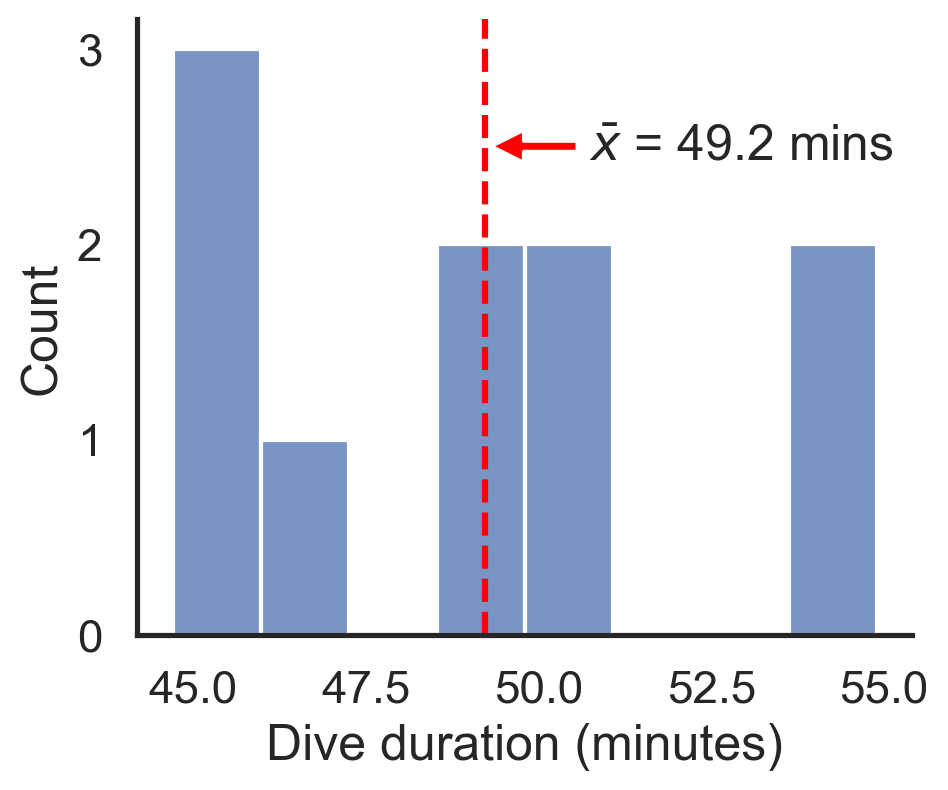

In [2]:
#| fig-align: center

fig, ax = plt.subplots(figsize=(5, 4))
dives = pd.read_csv('../../Datasets/weddell_seal_dives.csv')

xbar = dives['dive_duration_min'].mean()

ax = sns.histplot(dives['dive_duration_min'], bins=8, ax=ax)
ax.set_xlabel('Dive duration (minutes)')
ax.axvline(xbar, color='red', linestyle='--')
ax.annotate(fr'$\bar{{x}}$ = {xbar:.1f} mins', xy=(xbar, 2.5), xytext=(xbar + 1.5, 2.5),
            arrowprops=dict(facecolor='red', shrink=0.05), va='center');
fig.savefig('Images/fig1.png', bbox_inches='tight')

- The mean dive duration of this sample is 49.2 minutes
- But we want to know the overall mean duration of all Weddell seal dives
- This is called the **population mean**, usually denoted $\mu$

### Distribution of dive durations {.smaller}

![](Images/fig1.png){fig-align="center"}

- A **point estimate** of the population mean is usually denoted $\hat{\mu}$

- The hat symbol above $\hat{\mu}$ shows that this is an **estimate** of the population mean $\mu$

- The point estimate of the population mean equals the sample mean:

    $$\hat{\mu} = \bar{x} = 49.2\, \text{mins}$$


### A point estimate is not enough information

::: {.fragment .fade-in .center .orange}
But what if the marine biologists sampled a different set of 10 weddell seal dives
:::

:::: {.columns}

::: {.column width="20%"}

Sample 1  |
--: |
49.5 |
46.3 |
50.2 |
54.6 |
45.8 |
45.8 |
54.9 |
50.8 |
44.7 |
49.7 |
$\bar{x}_1=$ **49.2** |

:::
::: {.column width="20%" .fragment .fade-in}

Sample 2  |
--: |
44.7 |
49.3 |
48.2 |
37.4 |
38.4 |
44.2 |
41.9 |
48.6 |
42.5 |
54.3 |
$\bar{x}_2=$ **45.0** |

:::
::: {.column width="20%" .fragment .fade-in }

Sample 3 |
--: |
45.7 |
43.4 |
47.3 |
39.9 |
44.3 |
44.3 |
46.5 |
43.2 |
45.0 |
44.0 |
$\bar{x}_3=$ **44.4** |

:::
::: {.column width="40%" .fragment .fade-in  .orange}
Three different point estimates
:::
::::



### A point estimate is not enough information

- We have just one point estimate of the population mean ($\hat{\mu} =$  49.2 minutes)
- But there is some uncertainty in its value because only 10 dives were recorded
- How much uncertainty is there? For example, is it:
    - 49.2 $\pm$ 10 mins (around 39 and 59 mins)?
    - 49.2 $\pm$ 1 mins (around 48 and 50 mins)?
    - 49.2 $\pm$ 0.1 mins (around 49.1 and 49.3 mins)?

- We need to quantify the uncertainty in dive durations

### A point estimate is not enough information

- This uncertainty is called **sampling error**
    - So you can ask, how much error is there in the point estimate?
- The inverse of error is **precision**. 
    - So you can also ask, how precise is the point estimate?
- In conclusion, the full information we require is:
    - a point estimate of the population mean
    - the error (or precision) associated with that estimate
- [What determines the size of the error, and how do we calculate it?]{.orange}

### The error in an estimate of a population mean

$$
\begin{align*}
\text{error} &= \frac{\text{Standard deviation of the sample}}{\text{Square root of number of observations}} \\
\text{error} &= \frac{s}{\sqrt{n}}
\end{align*}
$$

::: {.fragment .center .orange}
Where does this formula come from?
:::


### Reminder: How do we measure variation?

- Variation is how spread out the data are around the mean

- There are three common measures of variation:

    - **Range**: maximum value minus minimum value 
    - **Inter quartile range**: the range containing the middle 50% of data 
    - **Standard deviation** (usually denoted $s$)

### Reminder: What is one standard deviation?

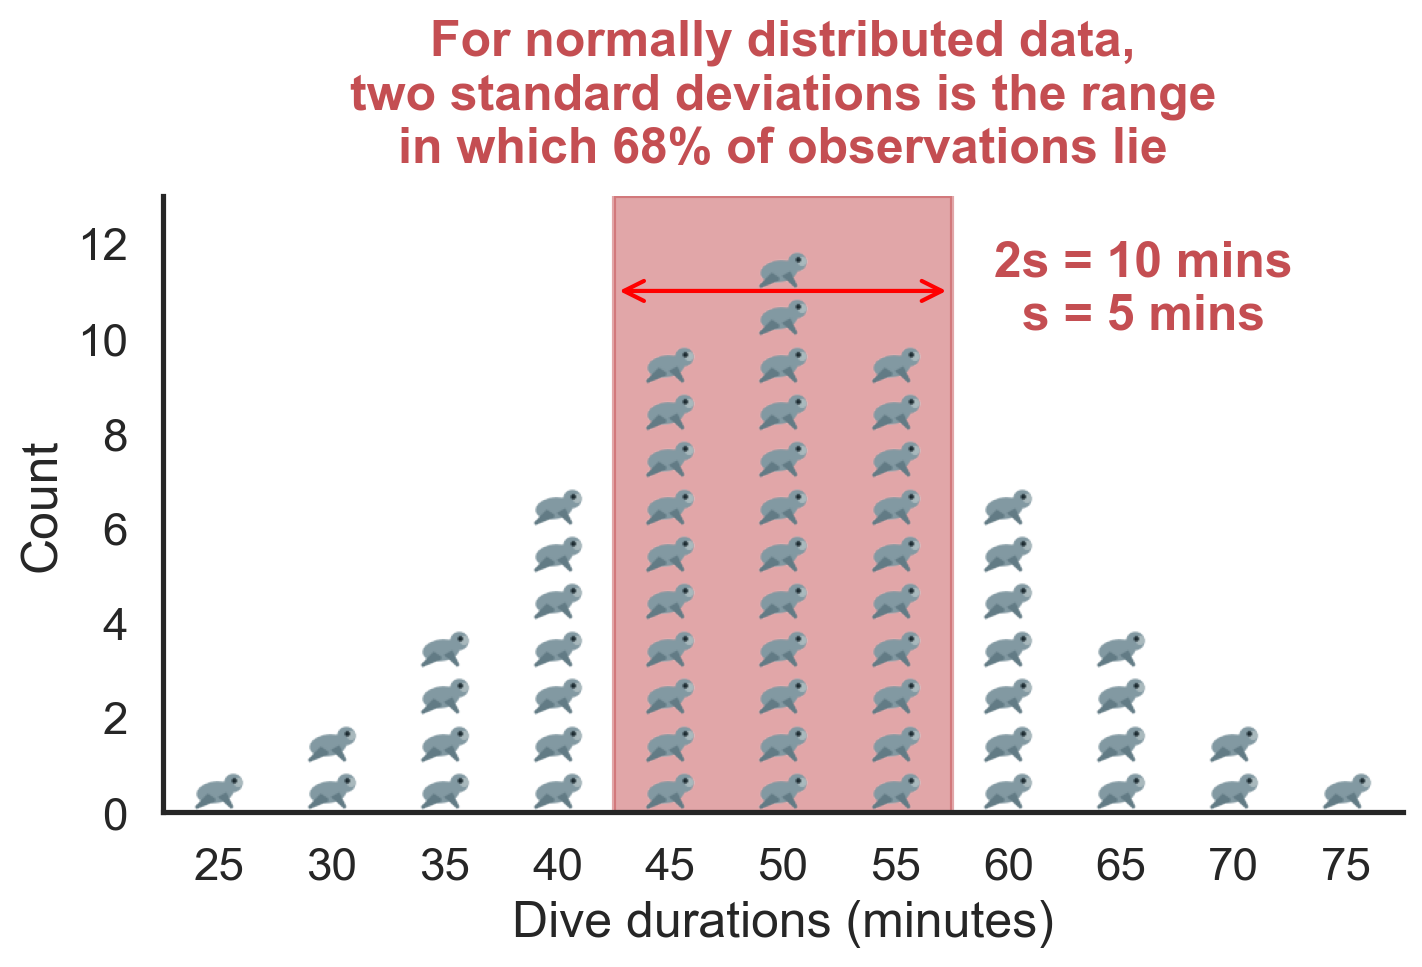

In [3]:
#| fig-align: center

# One seal represents one observation; symmetric counts make the bell shape clear.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.patches import Ellipse, Circle, Polygon

bin_centres = 5*np.arange(-5, 6)+50
seal_counts = np.array([1, 2, 4, 7, 10, 12, 10, 7, 4, 2, 1])
values = np.repeat(bin_centres, seal_counts)
bin_edges = 5*np.arange(-5.5, 6.5, 1)+50

fig, ax = plt.subplots(figsize=(8, 4))
counts, edges, _ = ax.hist(values, bins=bin_edges, color='w', edgecolor='none')

# Draw one tiny seal image, then stamp it once for each observation.
seal_fig, seal_ax = plt.subplots(figsize=(0.6, 0.36), dpi=100)
seal_ax.set_position([0, 0, 1, 1])
seal_ax.add_patch(Ellipse((0.43, 0.43), 0.62, 0.34, angle=8, color='#8299a2'))
seal_ax.add_patch(Polygon([[0.30, 0.37], [0.08, 0.15], [0.42, 0.29]], color='#627b85'))
seal_ax.add_patch(Polygon([[0.53, 0.34], [0.74, 0.15], [0.62, 0.39]], color='#627b85'))
seal_ax.add_patch(Circle((0.76, 0.60), 0.14, color='#8299a2'))
seal_ax.add_patch(Circle((0.85, 0.61), 0.055, color='#a9b9bd'))
seal_ax.add_patch(Circle((0.78, 0.64), 0.018, color='#17252b'))
seal_ax.set(xlim=(0, 1), ylim=(0, 1), aspect='equal')
seal_ax.axis('off')
seal_fig.patch.set_alpha(0)
seal_fig.canvas.draw()
seal_image = np.asarray(seal_fig.canvas.buffer_rgba()).copy()
plt.close(seal_fig)

for centre, count in zip((edges[:-1] + edges[1:]) / 2, counts.astype(int)):
    for stack_position in range(count):
        seal = OffsetImage(seal_image, zoom=0.55)
        ax.add_artist(AnnotationBbox(
            seal, (centre, stack_position + 0.5), frameon=False, pad=0
        ))

ax.set(xlim=(edges[0], edges[-1]), ylim=(0, max(seal_counts) + 1),
       xlabel='Dive durations (minutes)',
       ylabel='Count')
ax.set_xticks(bin_centres)
ax.set_yticks(np.arange(0, max(seal_counts) + 1, 2))
ax.text(s='For normally distributed data,\ntwo standard deviations is the range\nin which 68% of observations lie', x=50, y=13.5, va='bottom', ha='center', color='r', fontweight='bold')

ax.text(s='2s = 10 mins\ns = 5 mins', x=66, y=10, va='bottom', ha='center', color='r', fontweight='bold')
ax.axvspan(50-7.5, 57.5, color='r', alpha=0.5)
ax.annotate('', xy=(50-7.5, 11), xytext=(57.5, 11),
            arrowprops=dict(arrowstyle='<->', color='red'), va='center');


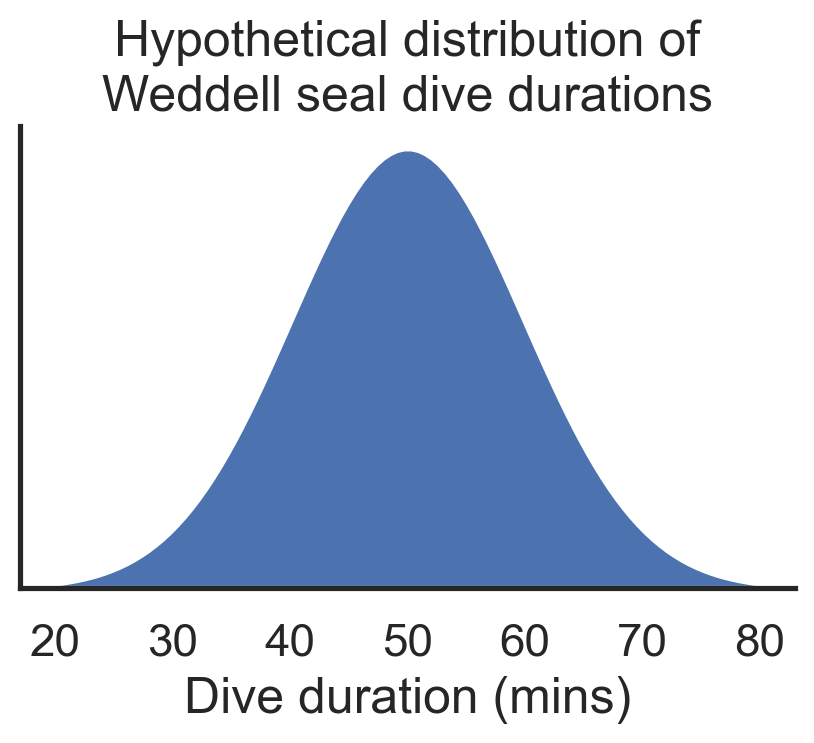

In [4]:
#| output: false

mu = 50
sigma = 10
fig, ax = plt.subplots(figsize=(5, 3))
xt = np.linspace(20, 80, 100)
yt = stats.norm.pdf(xt, mu, sigma)
ax.fill_between(xt, 0, yt, linewidth=2)
ax.set_xlabel('Dive duration (mins)')
ax.set_xticks(range(20, 90, 10))
ax.set_yticks([])
ax.set_ylim(0, ax.get_ylim()[1])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Hypothetical distribution of\nWeddell seal dive durations');
fig.savefig('Images/hypo_dives.png', bbox_inches='tight')

### A thought experiment {auto-animate=true}

::: {.fragment}
Let's assume
:::

- dive durations are normally distributed (bell-shaped)
- the population mean dive duration of weddell seals (μ) is 50 minutes
- the population variation (standard deviation) in dive duration (σ) is 10 minutes

::: {.fragment}
![](Images/hypo_dives.png){#graph1 fig-align="center"}
:::

### Monte-Carlo simulation {auto-animate=true}

:::: {.columns}
::: {.column width="20%"}
![](Images/hypo_dives.png){#graph1 fig-align="center"}
:::
::: {.column width="80%"}
- Sample 100 random dive durations from this normal distribution
:::
::::

::: {.fragment}

In [5]:
#| echo: true
#| output-location: fragment

from numpy.random import normal

x_1 = normal(loc=50, scale=10, size=100)

print(x_1.round(1))



[41.9 54.2 39.1 63.6 48.3 36.8 46.1 36.  54.5 73.4 52.4 59.8 49.4 54.4 39.9 47.1 42.8 46.7 49.9 50.6
 59.3 58.7 53.2 67.6 62.5 43.3 52.5 61.9 42.8 50.9 57.5 44.1 49.2 53.6 51.5 52.1 60.  48.3 44.1 51.9
 44.2 57.  72.2 45.4 39.  56.9 46.5 62.9 48.  53.8 53.7 31.7 83.  57.8 48.7 40.8 40.  54.  47.6 31.7
 30.1 54.2 64.3 55.2 46.6 48.4 41.2 61.6 69.3 41.8 56.2 36.  71.  53.6 43.2 34.6 74.7 55.8 36.  32.3
 51.7 41.6 60.5 55.7 75.2 53.9 58.6 40.8 53.2 54.  47.3 53.9 40.1 57.8 52.6 57.7 40.8 54.8 40.2 45.4]


:::

### Monte-Carlo simulation {auto-animate=true}



In [6]:
print(x_1.round(1))

[41.9 54.2 39.1 63.6 48.3 36.8 46.1 36.  54.5 73.4 52.4 59.8 49.4 54.4 39.9 47.1 42.8 46.7 49.9 50.6
 59.3 58.7 53.2 67.6 62.5 43.3 52.5 61.9 42.8 50.9 57.5 44.1 49.2 53.6 51.5 52.1 60.  48.3 44.1 51.9
 44.2 57.  72.2 45.4 39.  56.9 46.5 62.9 48.  53.8 53.7 31.7 83.  57.8 48.7 40.8 40.  54.  47.6 31.7
 30.1 54.2 64.3 55.2 46.6 48.4 41.2 61.6 69.3 41.8 56.2 36.  71.  53.6 43.2 34.6 74.7 55.8 36.  32.3
 51.7 41.6 60.5 55.7 75.2 53.9 58.6 40.8 53.2 54.  47.3 53.9 40.1 57.8 52.6 57.7 40.8 54.8 40.2 45.4]


::: {.fragment}

Calculate the mean of the 100 dive durations

In [7]:
#| echo: true
#| output-location: fragment

xbar_1 = x_1.mean()

print(f'xbar = {xbar_1:.1f} mins')

xbar = 51.1 mins


:::

### Monte-Carlo simulation

Compare hypothetical population distribution with the random sample of 100 dives

::: {.nonincremental}
- Population mean $\mu=$ 50 mins, population st. dev. $\sigma=$ 10 mins
- Point estimate of population mean is $\hat{\mu}=\bar{x}=$ `{python} f'{xbar_1:.1f}'` mins
:::

:::: {.r-stack}
::: {.fragment}

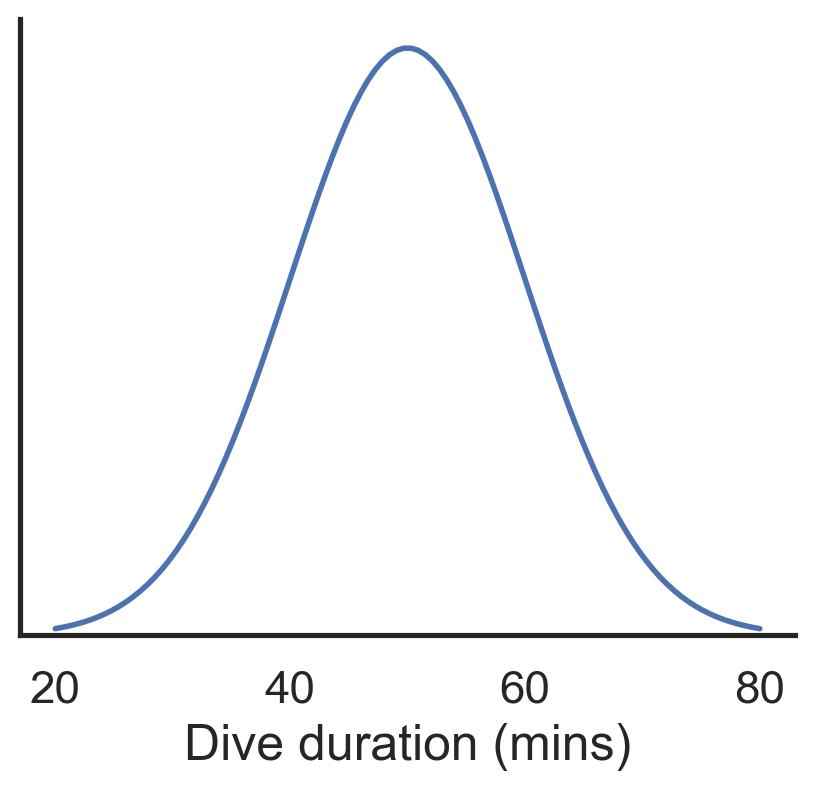

In [8]:
#| fig-align: center

mu = 50
sigma = 10
fig, ax = plt.subplots(figsize=(5, 4))
xt = np.linspace(20, 80, 100)
yt = stats.norm.pdf(xt, mu, sigma)
ax.plot(xt, yt, linewidth=2)
ax.set_xlabel('Dive duration (mins)')
ax.set_yticks([])
ax.set_ylabel('')
ax.set_ylim(0, ax.get_ylim()[1])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

:::
::: {.fragment}

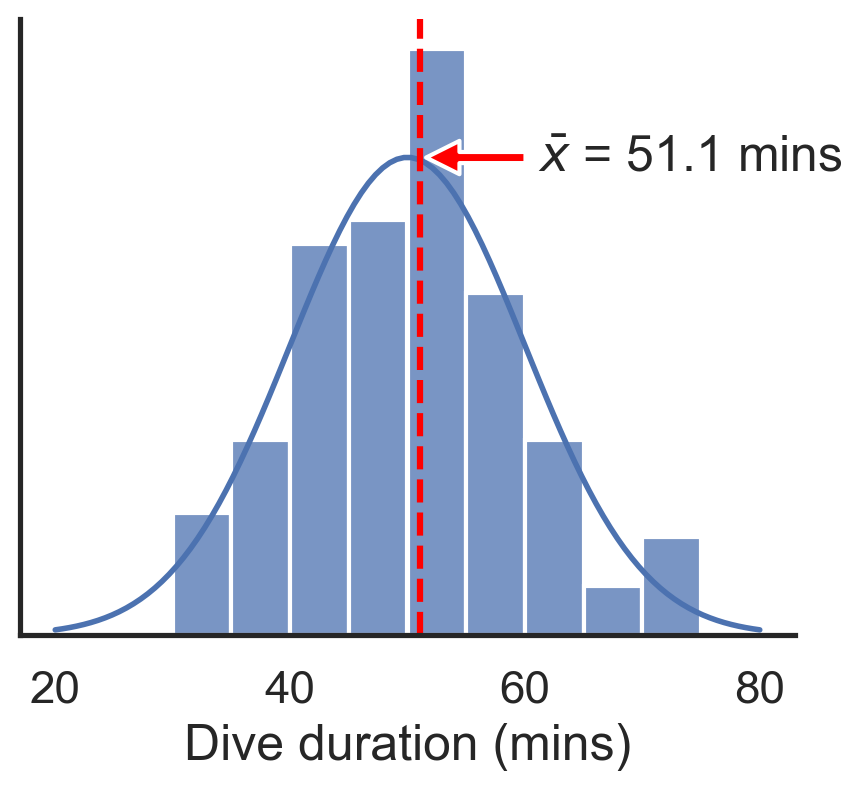

In [9]:
#| fig-align: center

mu = 50
sigma = 10
fig, ax = plt.subplots(figsize=(5, 4))
xt = np.linspace(20, 80, 100)
yt = stats.norm.pdf(xt, mu, sigma)
ax.plot(xt, yt, linewidth=2)
ax.set_xlabel('Dive duration (mins)')
ax.set_yticks([])
ax.set_ylabel('')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
sns.histplot(x_1, bins=range(20, 80, 5), ax=ax, stat='density');

ax.axvline(xbar_1, color='red', linestyle='--')
ax.annotate(fr'$\bar{{x}}$ = {xbar_1:.1f} mins', xy=(xbar_1, max(yt)), xytext=(xbar_1 + 10, max(yt)),
            arrowprops=dict(facecolor='red', shrink=0.05), va='center');

:::
::::

### Let's repeat this 200 times {auto-animate=true}

Create 200 samples of *n* = 100 random dive durations each from a normal distribution with mean 50 and standard deviation 10


In [10]:
#| echo: true

x_200 = normal(loc=50, scale=10, size=(200, 100))


::: {.fragment}
Calculate the 200 means of the 200 samples


In [11]:
#| echo: true
#| output-location: fragment

xbar_200 = x_200.mean(axis=1)

print(xbar_200.round(1))

[49.2 49.2 49.8 51.6 50.8 50.  48.7 50.  49.9 50.3 51.5 48.8 48.6 50.4 48.8 49.2 48.3 50.1 49.8 49.5
 50.4 48.6 48.9 48.1 50.3 50.5 50.5 50.1 49.1 50.9 48.  50.8 52.  51.  49.8 49.2 51.  48.7 50.6 48.9
 49.2 49.7 50.5 49.3 50.1 50.  50.5 51.  48.6 51.9 49.3 50.5 50.2 49.5 50.7 49.6 50.7 49.7 48.7 48.2
 49.8 49.7 51.8 49.1 51.1 52.1 50.7 49.8 48.6 47.8 49.7 49.2 51.2 50.3 49.8 49.4 49.8 48.6 51.  49.5
 49.2 48.5 52.  49.8 49.8 49.5 50.8 51.1 51.1 51.1 50.2 48.4 50.7 49.6 49.8 49.  50.4 48.5 51.5 49.2
 50.1 49.5 50.1 49.7 50.8 49.6 50.6 51.4 49.3 49.2 48.3 49.7 47.9 50.9 49.4 50.2 49.7 50.  50.6 52.5
 50.9 49.5 49.8 49.  50.2 50.4 50.9 49.8 50.2 49.8 50.8 49.2 50.3 51.  51.2 50.2 49.2 50.8 50.1 52.1
 50.8 49.1 51.5 49.7 50.4 51.4 49.8 50.7 50.1 50.  49.9 52.  50.9 49.6 51.8 49.  51.2 48.4 50.9 49.3
 50.  48.2 51.3 50.2 49.1 50.6 50.2 50.3 49.6 51.9 49.4 51.5 48.9 48.2 49.7 48.6 51.2 47.4 49.1 50.4
 50.4 49.4 50.  49.5 51.2 51.8 50.3 52.2 49.5 50.  49.8 49.3 50.3 49.8 51.4 50.2 49.9 51.2 

:::

### A histogram of the 200 sample means {auto-animate=true}

In [12]:
print(xbar_200.round(1))

[49.2 49.2 49.8 51.6 50.8 50.  48.7 50.  49.9 50.3 51.5 48.8 48.6 50.4 48.8 49.2 48.3 50.1 49.8 49.5
 50.4 48.6 48.9 48.1 50.3 50.5 50.5 50.1 49.1 50.9 48.  50.8 52.  51.  49.8 49.2 51.  48.7 50.6 48.9
 49.2 49.7 50.5 49.3 50.1 50.  50.5 51.  48.6 51.9 49.3 50.5 50.2 49.5 50.7 49.6 50.7 49.7 48.7 48.2
 49.8 49.7 51.8 49.1 51.1 52.1 50.7 49.8 48.6 47.8 49.7 49.2 51.2 50.3 49.8 49.4 49.8 48.6 51.  49.5
 49.2 48.5 52.  49.8 49.8 49.5 50.8 51.1 51.1 51.1 50.2 48.4 50.7 49.6 49.8 49.  50.4 48.5 51.5 49.2
 50.1 49.5 50.1 49.7 50.8 49.6 50.6 51.4 49.3 49.2 48.3 49.7 47.9 50.9 49.4 50.2 49.7 50.  50.6 52.5
 50.9 49.5 49.8 49.  50.2 50.4 50.9 49.8 50.2 49.8 50.8 49.2 50.3 51.  51.2 50.2 49.2 50.8 50.1 52.1
 50.8 49.1 51.5 49.7 50.4 51.4 49.8 50.7 50.1 50.  49.9 52.  50.9 49.6 51.8 49.  51.2 48.4 50.9 49.3
 50.  48.2 51.3 50.2 49.1 50.6 50.2 50.3 49.6 51.9 49.4 51.5 48.9 48.2 49.7 48.6 51.2 47.4 49.1 50.4
 50.4 49.4 50.  49.5 51.2 51.8 50.3 52.2 49.5 50.  49.8 49.3 50.3 49.8 51.4 50.2 49.9 51.2 

::: {.fragment}

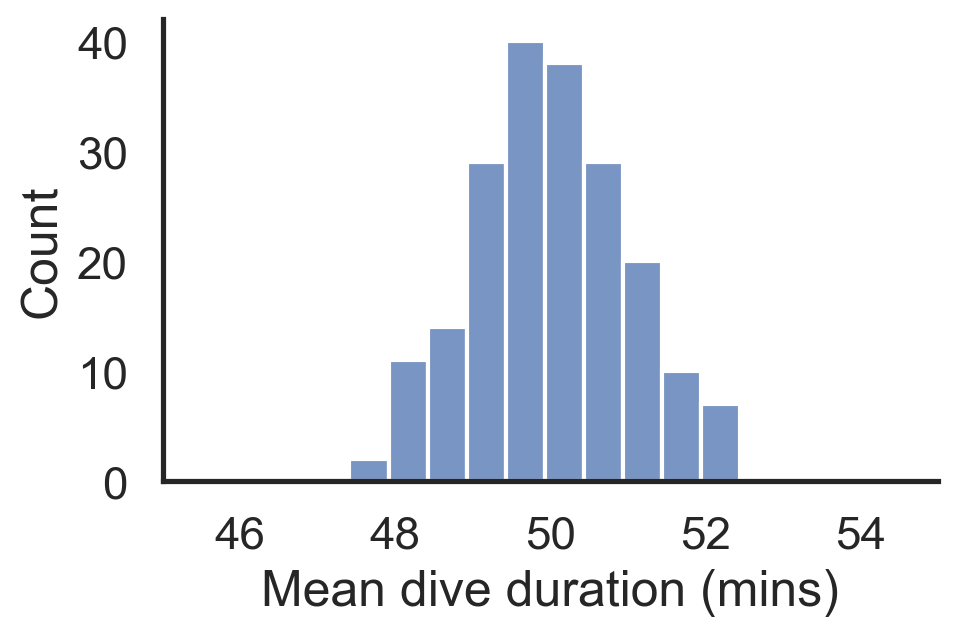

In [13]:
#| fig-align: center

fig, ax = plt.subplots(figsize=(5, 3))

sns.histplot(xbar_200, bins=10, ax=ax)
ax.set_xlabel('Mean dive duration (mins)');
ax.set_xlim(mu-5, mu+5);


:::

### Now sample 100 dives an infinite number of times

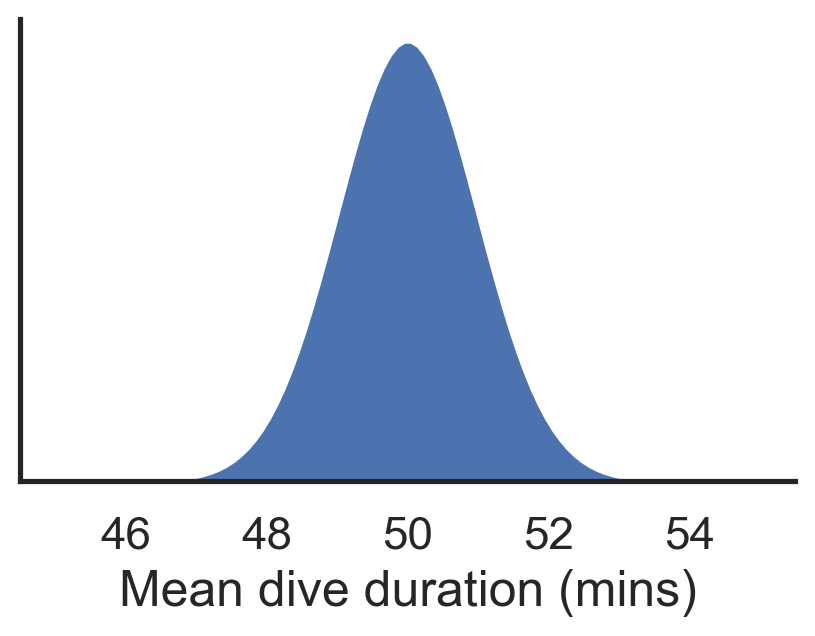

In [14]:
#| fig-align: center

fig, ax = plt.subplots(figsize=(5, 3))
sem_e = sigma/np.sqrt(100)
xt = np.linspace(mu-5*sem_e, mu+5*sem_e, 100)
yt = norm.pdf(xt, mu, sem_e)
ax.fill_between(xt, 0, yt)

ax.set_xlabel('Mean dive duration (mins)')
ax.set_xticks(range(46, 56, 2))
ax.set_yticks([])
ax.set_yticklabels([])
ax.set_ylim(0, ax.get_ylim()[1])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False);

::: {.fragment .center .orange}
This is called a **sampling distribution**
:::

### Do not confuse a data distribution with its sampling distribution

:::: {.columns}
::: {.column width="50%"}

- **Data distribution** is a histogram of the data from an experiment
- **Sampling distribution** is a hypothetical distribution of sample means of sample size *n*
    - we don't know what it is
    - we don't need to know what it is 
    - but it is a useful concept for thinking about the error in our estimates

:::
::: {.column width="50%"}

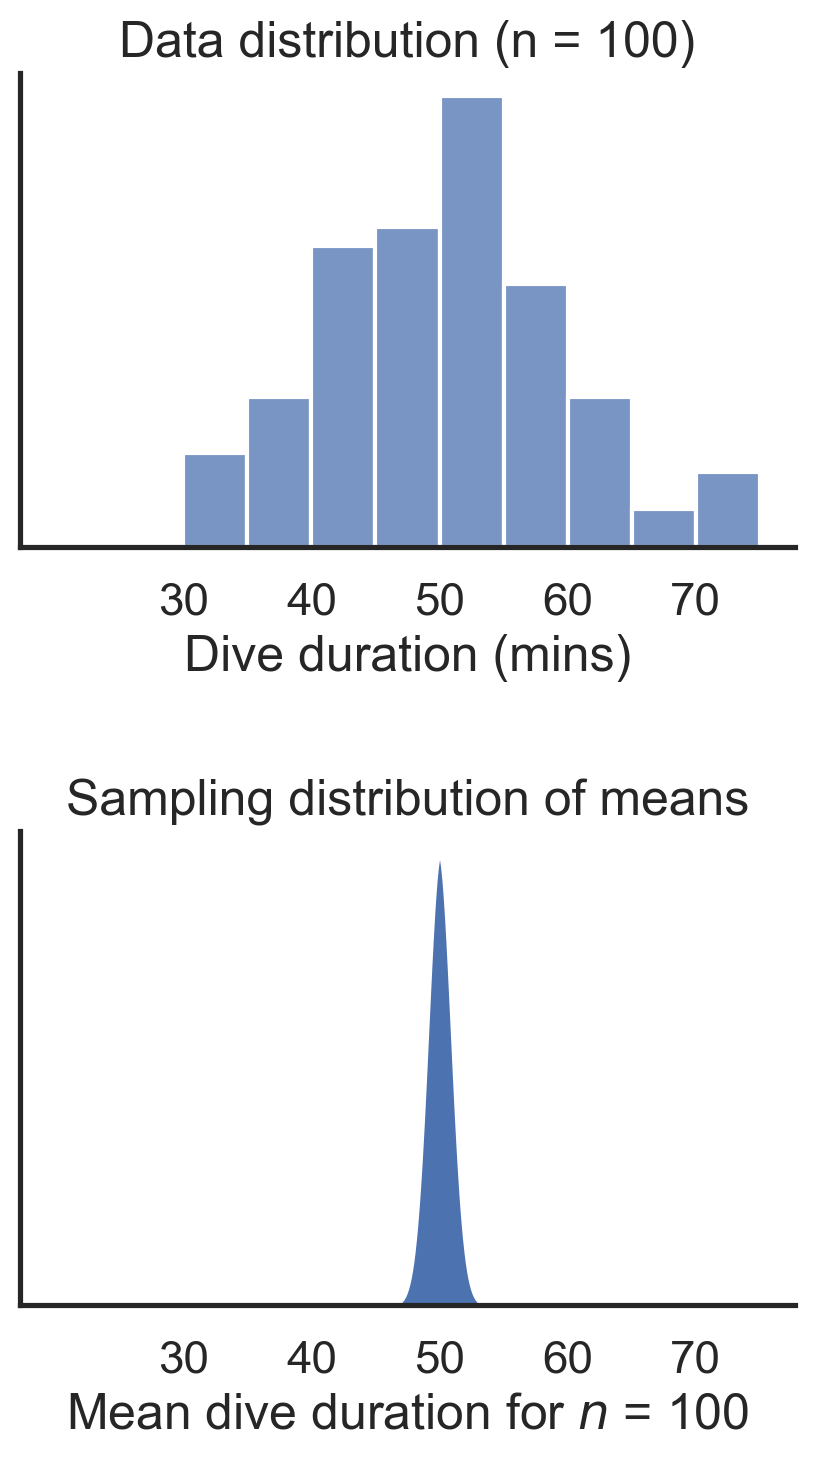

In [15]:
#| fig-align: center

fig, axs = plt.subplots(2, 1, figsize=(5, 8), sharex=True)
fig.subplots_adjust(hspace=0.6)
ax = axs[0]
ax.set_xlabel('Dive duration (mins)')
ax.tick_params(axis='x', labelbottom=True)
ax.set_xticks(range(20, 80, 10))
ax.set_xticklabels(range(20, 80, 10))
ax.set_yticks([])
ax.set_ylabel('')
ax.set_title('Data distribution (n = 100)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
sns.histplot(x_1, bins=range(20, 80, 5), ax=ax, stat='density');

ax = axs[1]
sem_e = sigma/np.sqrt(100)
xt = np.linspace(mu-5*sem_e, mu+5*sem_e, 100)
yt = norm.pdf(xt, mu, sem_e)
ax.fill_between(xt, 0, yt)

ax.set_xlabel('Mean dive duration for $n$ = 100')
ax.set_xticks(range(30, 80, 10))
ax.set_yticks([])
ax.set_ylabel('')
ax.set_ylim(0, ax.get_ylim()[1])
ax.set_title('Sampling distribution of means');


:::
::::

### The mean of our single sample lies within the sampling distribution

:::: {.columns}
::: {.column width="50%"}

- The **width** of the sampling distribution therefore tells us how much uncertainty (error) there is in our point estimate
- By convention we use the standard deviation of the sampling distribution as a measure of its width
- Therefore the error in our point estimate is the standard deviation (width) of the sampling distribution


:::
::: {.column width="50%"}

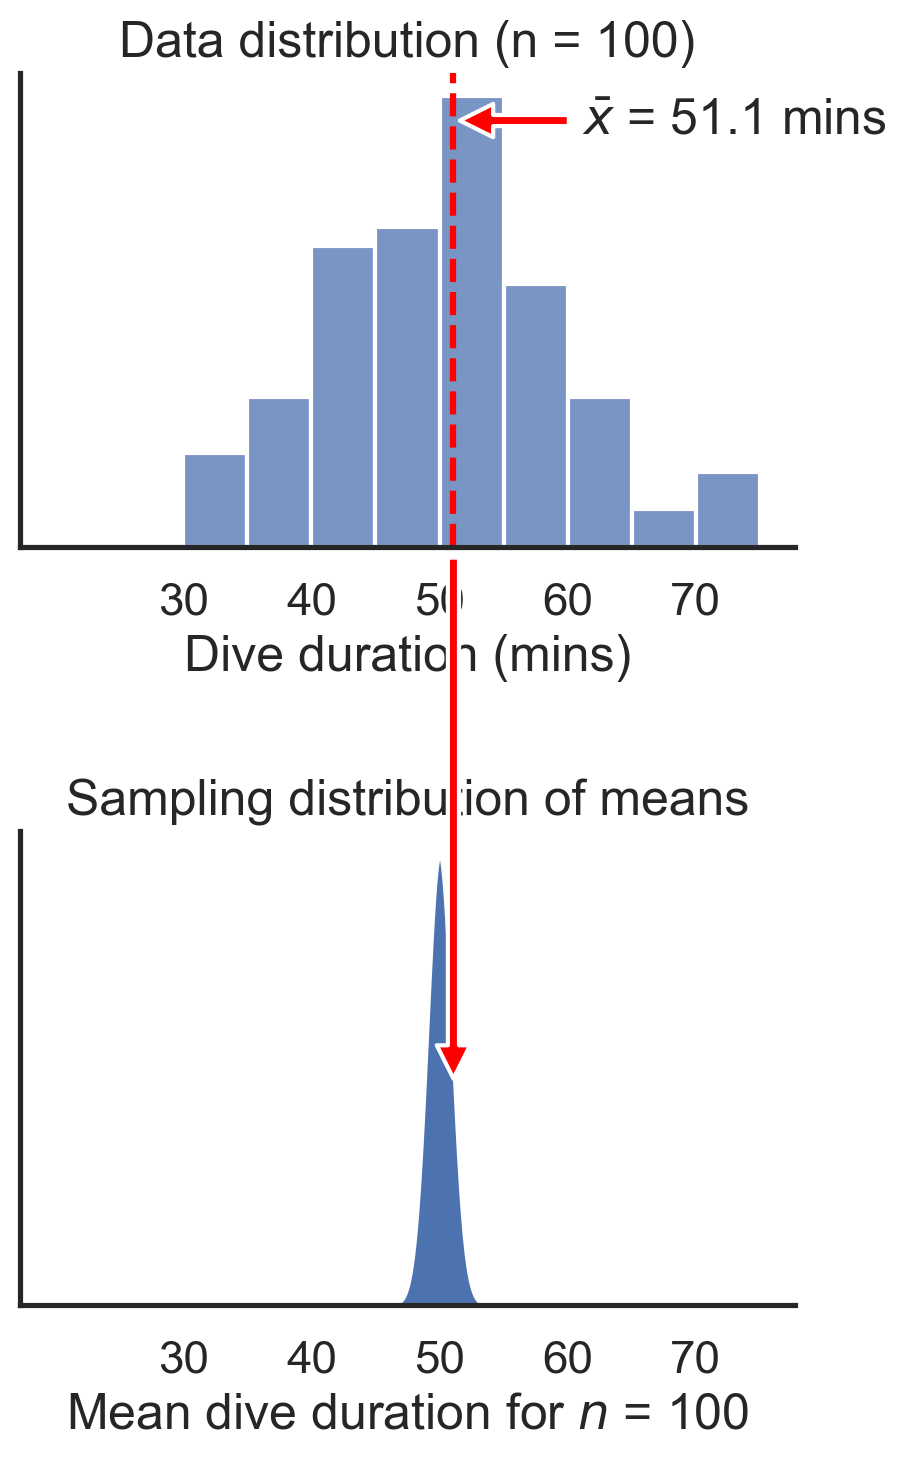

In [16]:
#| fig-align: center

fig, axs = plt.subplots(2, 1, figsize=(5, 8), sharex=True)
fig.subplots_adjust(hspace=0.6)
ax = axs[0]
ax.set_xlabel('Dive duration (mins)')
ax.tick_params(axis='x', labelbottom=True)
ax.set_xticks(range(20, 80, 10))
ax.set_xticklabels(range(20, 80, 10))
ax.set_yticks([])
ax.set_ylabel('')
ax.set_title('Data distribution (n = 100)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
sns.histplot(x_1, bins=range(20, 80, 5), ax=ax, stat='density');

ax.axvline(xbar_1, color='red', linestyle='--')
yt = ax.get_ylim()[1]
ax.annotate(fr'$\bar{{x}}$ = {xbar_1:.1f} mins', xy=(xbar_1, yt*0.9), xytext=(xbar_1 + 10, yt*0.9), arrowprops=dict(facecolor='red', shrink=0.05), va='center');


ax = axs[1]
sem_e = sigma/np.sqrt(100)
xt = np.linspace(mu-5*sem_e, mu+5*sem_e, 100)
yt = norm.pdf(xt, mu, sem_e)
ax.fill_between(xt, 0, yt)

ax.set_xlabel('Mean dive duration for $n$ = 100')
ax.set_xticks(range(30, 80, 10))
ax.set_yticks([])
ax.set_ylabel('')
ax.set_ylim(0, ax.get_ylim()[1])
ax.set_title('Sampling distribution of means')

ax.annotate('', xy=(xbar_1, 0.2), xytext=(xbar_1, 0.66), zorder=1000, arrowprops=dict(facecolor='red', edgecolor='w'), va='center');



:::
::::

### Standard error of the mean

The technical name for the standard deviation of the sampling distribution is the **Standard error of the mean (SEM)**

- "standard" because standard deviation is used to measure variability
- "error" because it tells us the error in our point estimate of the mean, $\hat{\mu}$


### Formula for the SEM {auto-animate=true}

It turns out, and you can prove this mathematically, that

$$\text{SEM} = \frac{\text{Population standard deviation of dive durations}}{\text{Square root of number of observations}}=\frac{\sigma}{\sqrt{n}}$$


### But there's a problem {auto-animate=true}

$$\text{SEM} = \frac{\text{Population standard deviation of dive durations}}{\text{Square root of number of observations}}=\frac{\sigma}{\sqrt{n}}$$

- We don't actually know the value of the **population** standard deviation of dive durations, σ

- But we do know the **sample** standard deviation of dive durations, *s*. 

::: {.fragment}

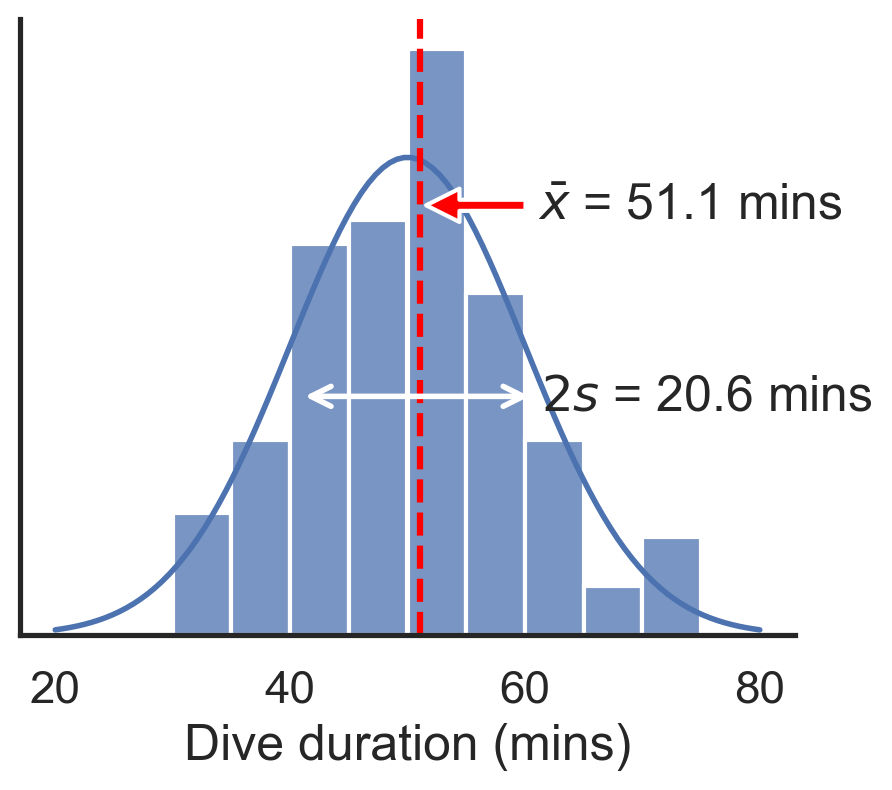

In [17]:
#| fig-align: center

mu = 50
sigma = 10
fig, ax = plt.subplots(figsize=(5, 4))
xt = np.linspace(20, 80, 100)
yt = stats.norm.pdf(xt, mu, sigma)
ax.plot(xt, yt, linewidth=2)
ax.set_xlabel('Dive duration (mins)')
ax.set_yticks([])
ax.set_ylabel('')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
sns.histplot(x_1, bins=range(20, 80, 5), ax=ax, stat='density');

s_1 = x_1.std()
ax.axvline(xbar_1, color='red', linestyle='--')
ax.annotate(fr'$\bar{{x}}$ = {xbar_1:.1f} mins', xy=(xbar_1, max(yt)*0.9), xytext=(xbar_1 + 10, max(yt)*0.9), arrowprops=dict(facecolor='red', shrink=0.05), va='center');

ax.annotate(fr'$2s$ = {2*s_1:.1f} mins', xy=(xbar_1-s_1, 0.5*max(yt)), xytext=(xbar_1+s_1, 0.5*max(yt)),
            arrowprops=dict(arrowstyle='<->', color='w', lw=2), va='center');


:::

### Solution

$$\text{SEM} = \frac{\text{Population standard deviation of dive durations}}{\text{Square root of number of observations}}=\frac{\sigma}{\sqrt{n}}$$

- The sample standard deviation (*s*) is an estimate of the population standard deviation (σ)

- Use *s* instead of σ to calculate SEM:

::: {.fragment}
$$\text{SEM} \approx \frac{\text{Sample standard deviation of observed dive durations}}{\text{Square root of number of observations}}=\frac{s}{\sqrt{n}}$$
:::

### End of the thought experiment

#### What have we learnt?

- We pretended to sample our population an infinite number of times
- For each sample we calculated its mean
- We plotted the distribution of these means
- This distribution is called a sampling distribution

::: {.fragment}

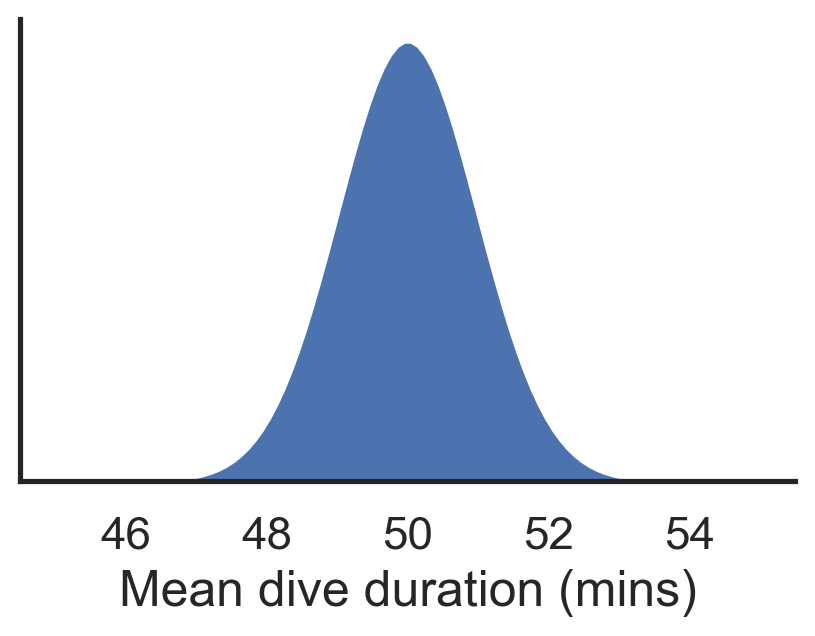

In [18]:
#| fig-align: center

fig, ax = plt.subplots(figsize=(5, 3))
sem_e = sigma/np.sqrt(100)
xt = np.linspace(mu-5*sem_e, mu+5*sem_e, 100)
yt = norm.pdf(xt, mu, sem_e)
ax.fill_between(xt, 0, yt)

ax.set_xlabel('Mean dive duration (mins)')
ax.set_xticks(range(46, 56, 2))
ax.set_yticks([])
ax.set_yticklabels([])
ax.set_ylim(0, ax.get_ylim()[1])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False);

:::

### End of the thought experiment

#### What have we learnt?

- The width of the sampling distribution tells us how much error there is in the point estimate of the population mean
- We use the standard deviation of the sampling distribution as a measure of its width
- This is called the standard error of the mean
- Because we don't know the population standard deviation we use its estimate, the sample standard deviation
- The formula for the standard error of the mean is
    $$\text{SEM} \approx \frac{\text{Sample standard deviation of observed dive durations}}{\text{Square root of number of observations}}=\frac{s}{\sqrt{n}}$$



### Interactive plot of the sampling distribution

The notebook [estimate.ipynb](estimate.ipynb) has an interactive plot of the sampling distribution.

### Back to the original data of dive durations

:::: {.columns}
::: {.column width="50%"}

![](Images/fig1.png)

:::
::: {.column width="50%"}
| Dive duration (mins) |
| --: |
| 49.5 |
| 46.3 |
| 50.2 |
| 54.6 |
| 45.8 |
| 45.8 |
| 54.9 |
| 50.8 |
| 44.7 |
| 49.7 |
| $\bar{x}=$ **49.2** |
:::
::::

### The final estimate with error

:::: {.columns}
::: {.column width="50%"}

![](Images/fig1.png)

:::
::: {.column width="50%"}
::: {.fragment}


In [19]:
#| echo: true
#| output-location: fragment

dives = pd.read_csv('../../Datasets/weddell_seal_dives.csv')

n = dives['dive_duration_min'].count()
xbar = dives['dive_duration_min'].mean()
s = dives['dive_duration_min'].std()

# Either
sem = s/np.sqrt(n)
# or
sem = dives['dive_duration_min'].sem()

print(f'n: {n}')
print(f'mean: {xbar:.2f} mins')
print(f'std: {s:.2f} mins')
print(f'SEM: {sem:.2f} mins')

n: 10
mean: 49.23 mins
std: 3.61 mins
SEM: 1.14 mins


:::
:::
::::

### The final estimate with error

:::: {.columns}
::: {.column width="50%"}

![](Images/fig1.png)

:::
::: {.column width="50%"}

The estimated mean dive duration of Weddell seals is

$\hat{\mu}=$ `{python} f'{xbar:.1f} ± {sem:.1f}'` mins

Average dive durations of Weddell seals is 49 minutes plus or minus 1 minute.
:::
::::

### A common alternative: the 95% CI

::: {.fragment}

$$\hat{\mu} = \bar{x}\pm\text{SEM}$$

is just one way of reporting a point estimate of the population mean with error.

:::
::: {.fragment}

$$\hat{\mu} = \bar{x}\pm t_{n-1}\times\text{SEM}$$

is another common way and is called a 95% confidence interval (CI)

:::

### A common alternative: the 95% CI

$$\hat{\mu} = \bar{x}\pm t_{n-1}\times\text{SEM}$$

The factor $t_{n-1}$ is a correction factor for small sample sizes.

*n* | $t_{n-1}$
--: | --:
2 | 12.71
5 | 2.78
10 | 2.26
20 | 2.09
50 | 2.01
100 | 1.98
500+ | 1.96


### A common alternative: the 95% CI

##### A rule of thumb: 

For samples with more than 20 observations $t_{n-1}$ is about 2, i.e.,
 
$$\hat{\mu} = \bar{x}\pm 2\times\text{SEM}$$

::: {.fragment}
For large enough samples, the 95% CI is about two times larger than the standard error.
:::

### A common alternative: the 95% CI

The code to calculate $t_{n-1}$ is

In [20]:
#| echo: true
#| output-location: fragment

from scipy.stats import t

t_df = t.ppf(0.975, df=9)

print(f't_df = {t_df:.2f}')

t_df = 2.26


::: {.fragment}
`df` stands for "degrees of freedom". In this case it is one less than the sample size. 
:::


### A common alternative: the 95% CI

For *n* = 10, $t_{9}=$ `{python} f'{t_df:.2f}'`

::: {.fragment}
95% CI are usually written as a range from the low bound to the high bound. 
:::

- low bound = $\bar{x} - t_{n-1}\times\text{SEM}$
- high bound = $\bar{x} + t_{n-1}\times\text{SEM}$

::: {.fragment}

In [21]:
#| echo: true
#| output-location: fragment

ci_low = xbar - t_df * sem
ci_high = xbar + t_df * sem

print(f'95% CI: [{ci_low:.1f}, {ci_high:.1f}] mins')


95% CI: [46.6, 51.8] mins


:::

### A common alternative: the 95% CI

- The 95% CI of dive durations is [`{python} f'{ci_low:.1f}'`, `{python} f'{ci_high:.1f}'`] mins.

- Many statistical software packages automatically calculate SEM and 95% CIs for you.

### Visualising point estimates and their errors {auto-animate=true}

- Errors are graphically represented as error bars
- Barplots are a common method

::: {.fragment}

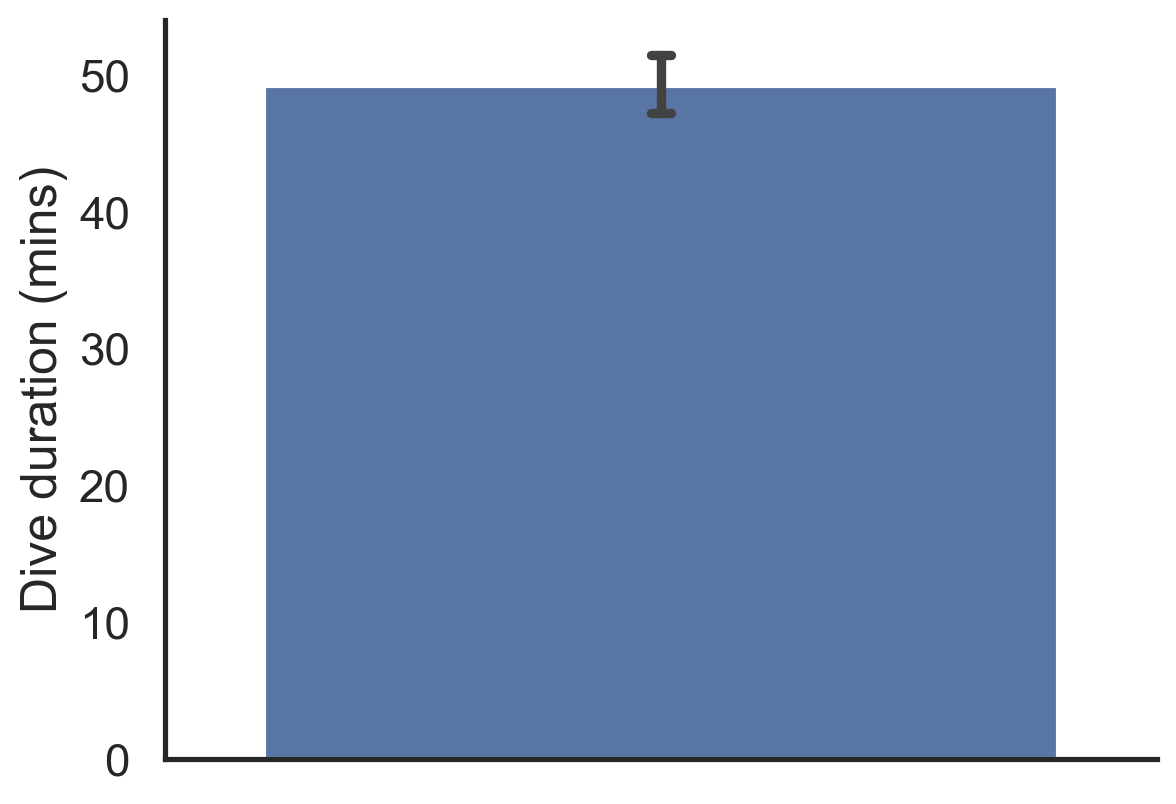

In [22]:
#| echo: true
#| fig-align: center
#| output-location: fragment
#| data-id: graph2

ax = sns.barplot(data=dives, y='dive_duration_min', capsize=.02);
ax.set_ylabel('Dive duration (mins)');

:::

### Error bars in a bar plot

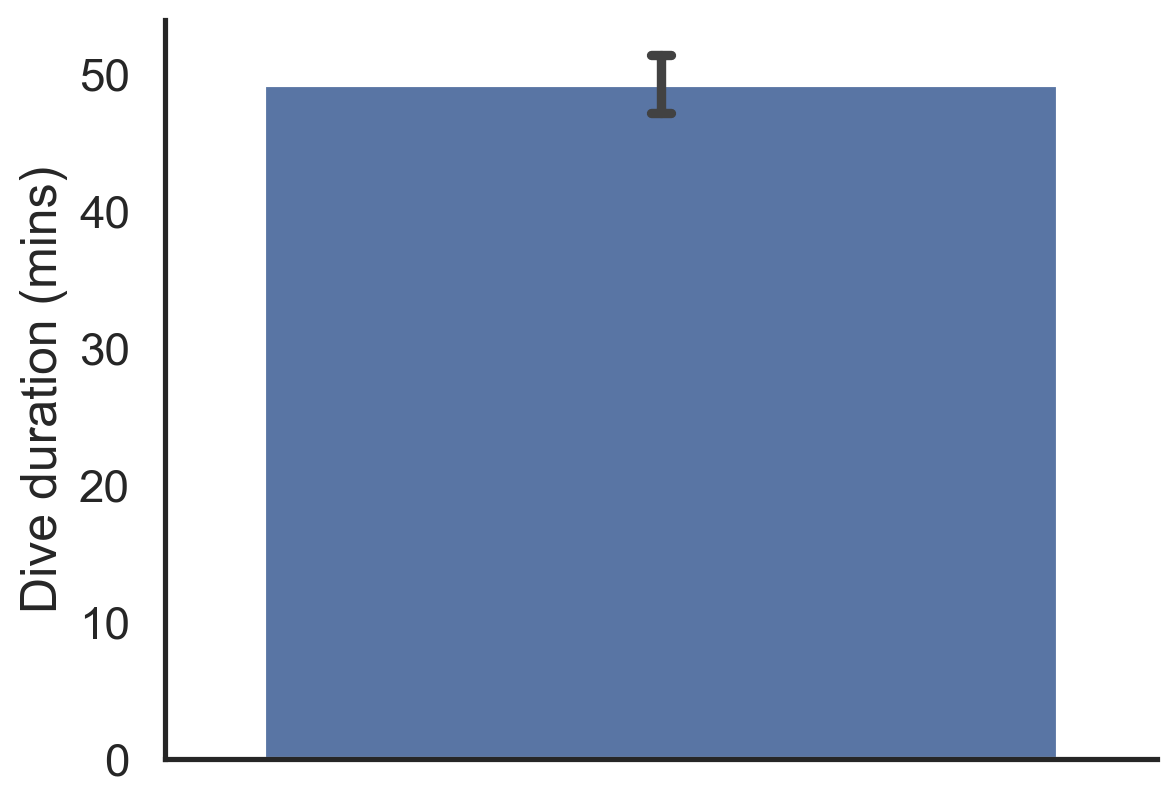

In [23]:
#| fig-align: center

ax = sns.barplot(data=dives, y='dive_duration_min', capsize=.02);
ax.set_ylabel('Dive duration (mins)');


- A bar plot creates a bar with the bottom at zero and the top at the point estimate. The errorbar extends from the low bound to the high bound of the 95% CI.
- If there is not too many data points it is also a good idea to include them in the plot so that people can see the position and spread of the raw data.


### Error bars in a bar plot

These plots are more useful when comparing things. Dive durations of different seal species, for example.

In [24]:
x1 = normal(90, 20, size=10)
x2 = normal(50, 10, size=10)
x3 = normal(30, 10, size=10)
x4 = normal(17, 5, size=10)
x5 = normal(12, 4, size=10)
dives_cmp = pd.concat([
    pd.DataFrame({'dive_duration_min': x1, 'group': 'Elephant seal'}),
    pd.DataFrame({'dive_duration_min': x2, 'group': 'Weddell seal'}),
    pd.DataFrame({'dive_duration_min': x3, 'group': 'Harbor seal'}),
    pd.DataFrame({'dive_duration_min': x4, 'group': 'Leopard seal'}),
    pd.DataFrame({'dive_duration_min': x5, 'group': 'Crabeater seal'})
], ignore_index=True)

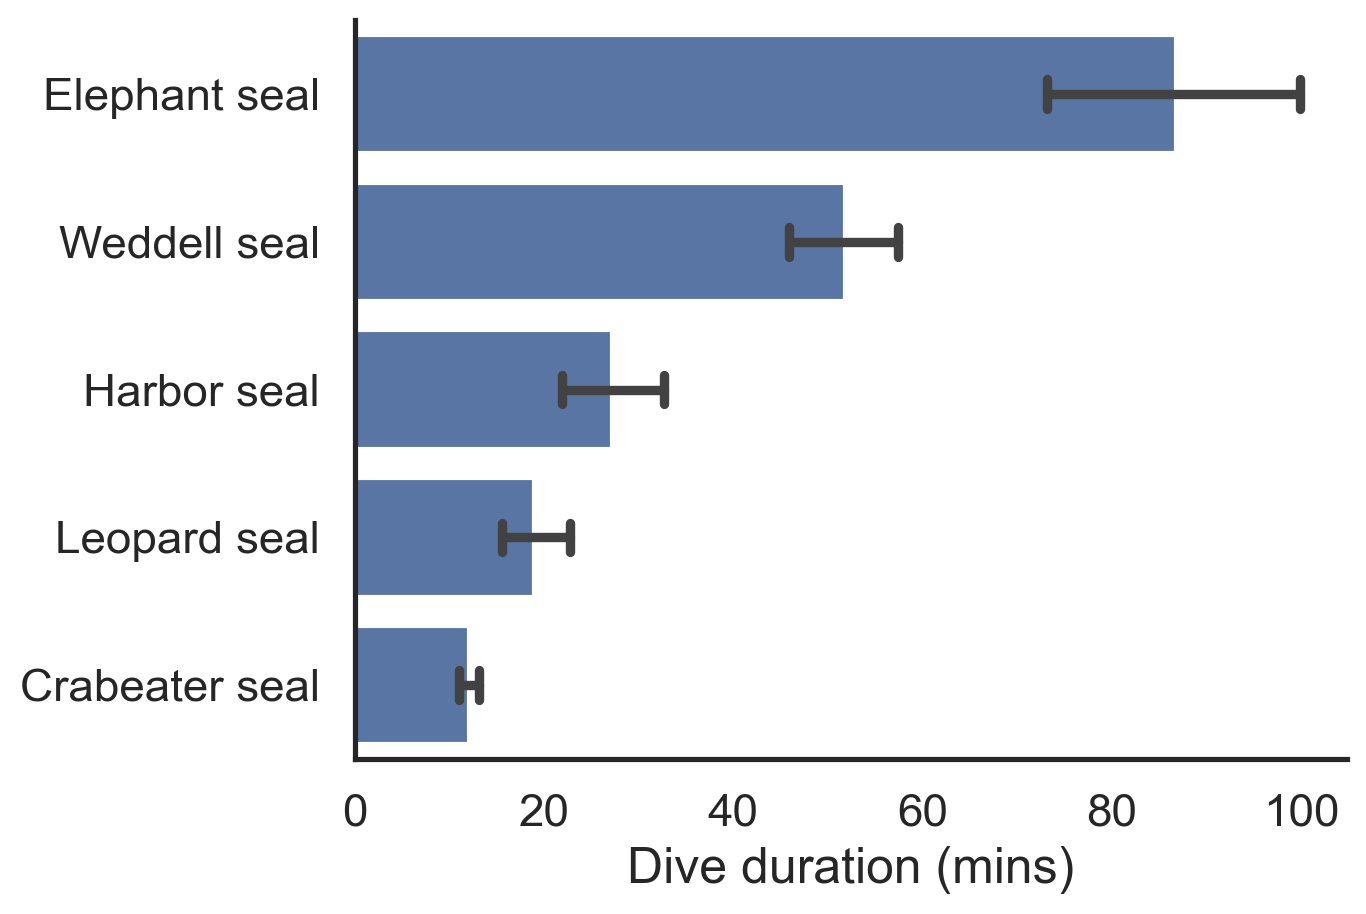

In [25]:
#| fig-align: center

ax = sns.barplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2)
# sns.swarmplot(data=dives_cmp, y='group', x='dive_duration_min', color='C2', marker='o', facecolor='w', edgecolor='C1', linewidth=2)
ax.set_xlabel('Dive duration (mins)');
ax.set_ylabel('');
xlims = ax.get_xlim()

### Error bars in a point plot

A point plot just plots a circle at the point estimate. This gives a less cluttered figure than a bar plot.

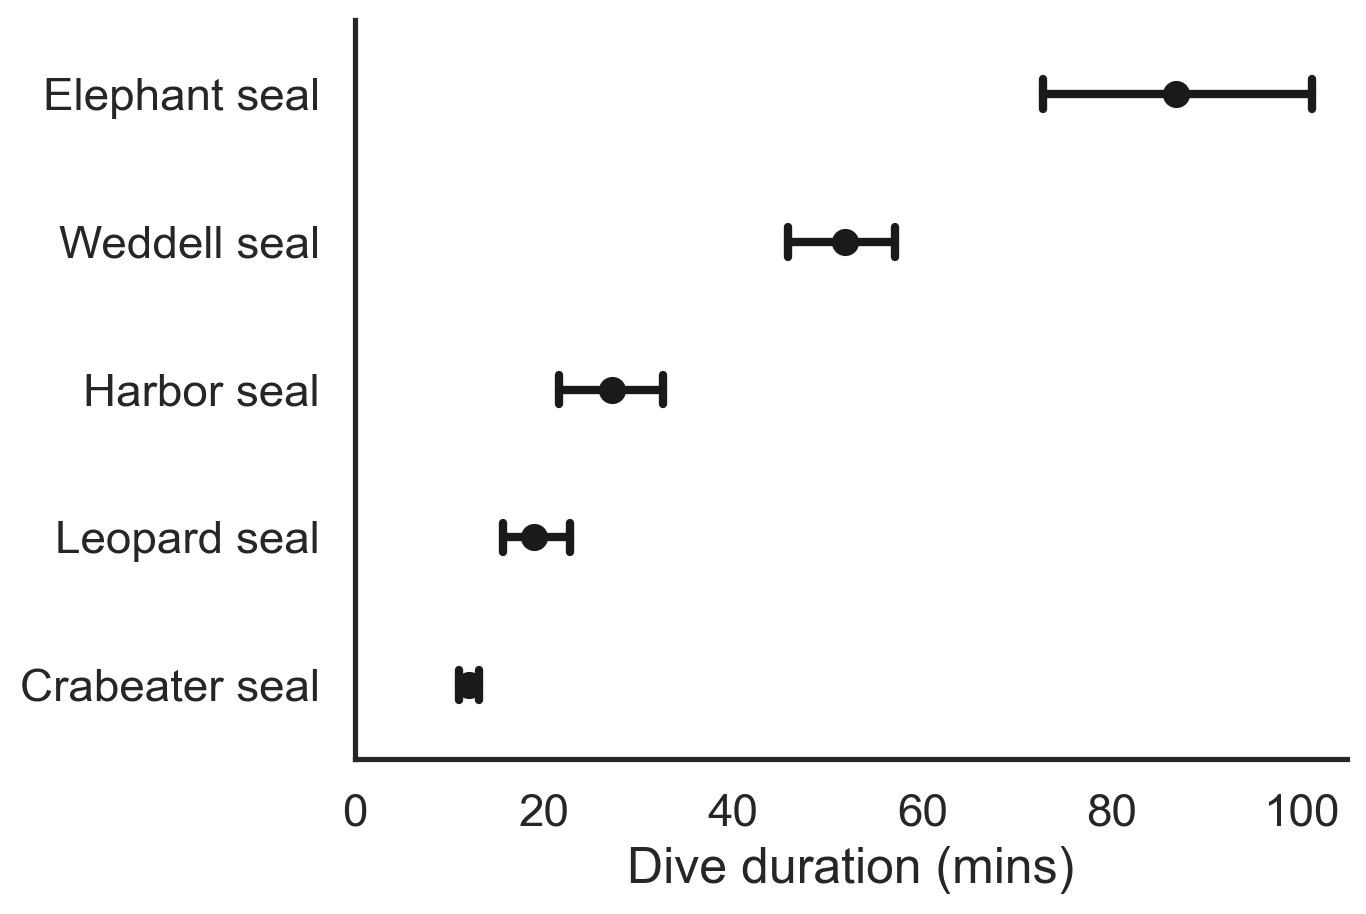

In [26]:
#| fig-align: center

ax = sns.pointplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2, color="k", linestyle="none", marker="o", linewidth=3)
# sns.swarmplot(data=dives_cmp, y='group', x='dive_duration_min', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
ax.set_xlim(*xlims)
ax.set_xlabel('Dive duration (mins)');
ax.set_ylabel('');

### Include the data

If there are not too many data including them can be useful to see the distribution of the data 

/home/njs/miniconda3/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 10.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


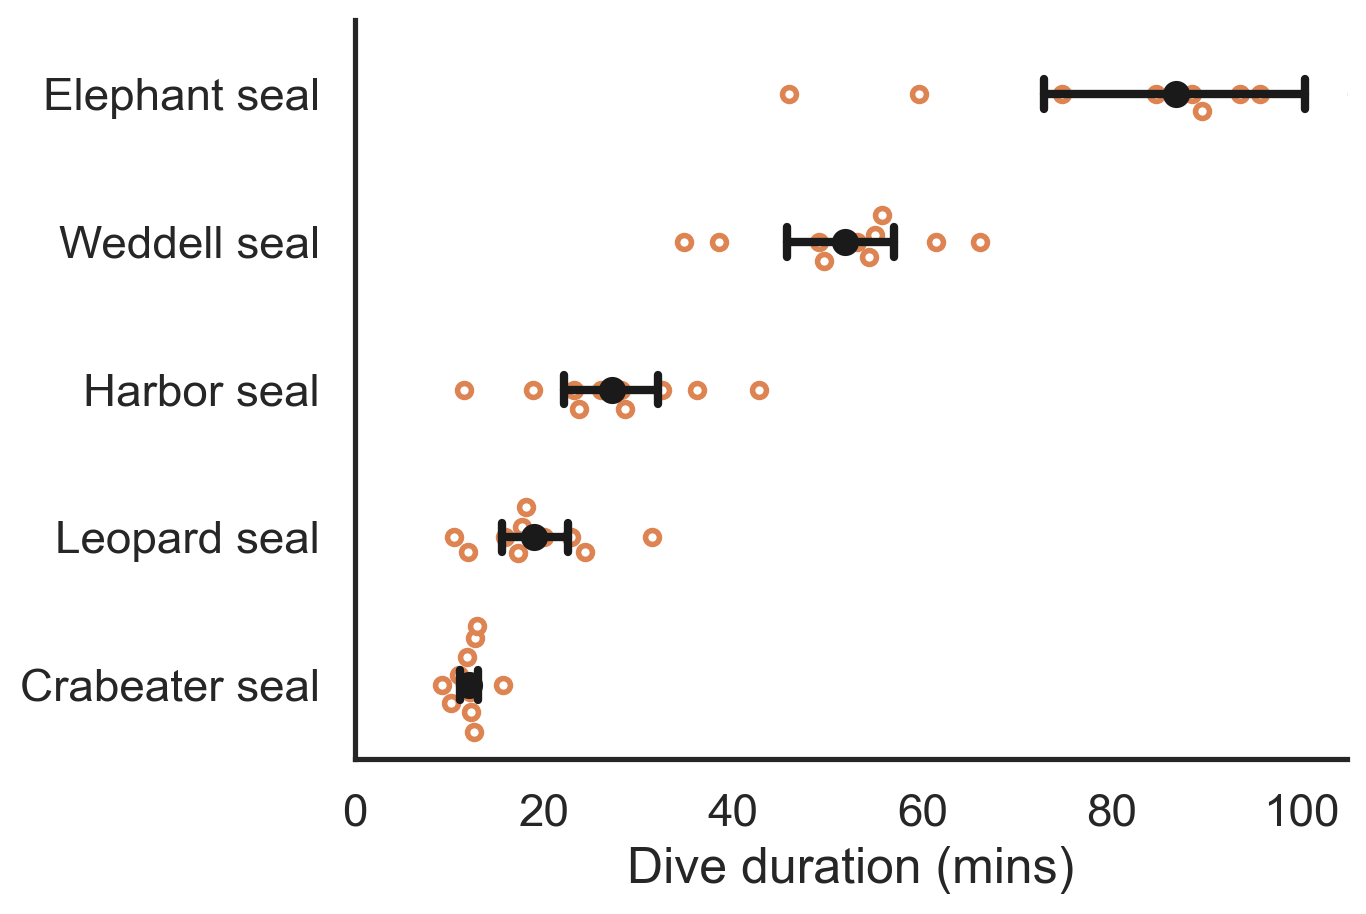

In [27]:
#| fig-align: center

ax = sns.pointplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2, color="k", linestyle="none", marker="o", linewidth=3)
sns.swarmplot(data=dives_cmp, y='group', x='dive_duration_min', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
ax.set_xlim(*xlims)
ax.set_xlabel('Dive duration (mins)')
ax.set_ylabel('');

### Error bars in a point plot

::: {.callout-important}
Always state in the figure caption what errorbars represent (SEM, 95% CI) so that readers know how to interpret them.
:::

/home/njs/miniconda3/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 10.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


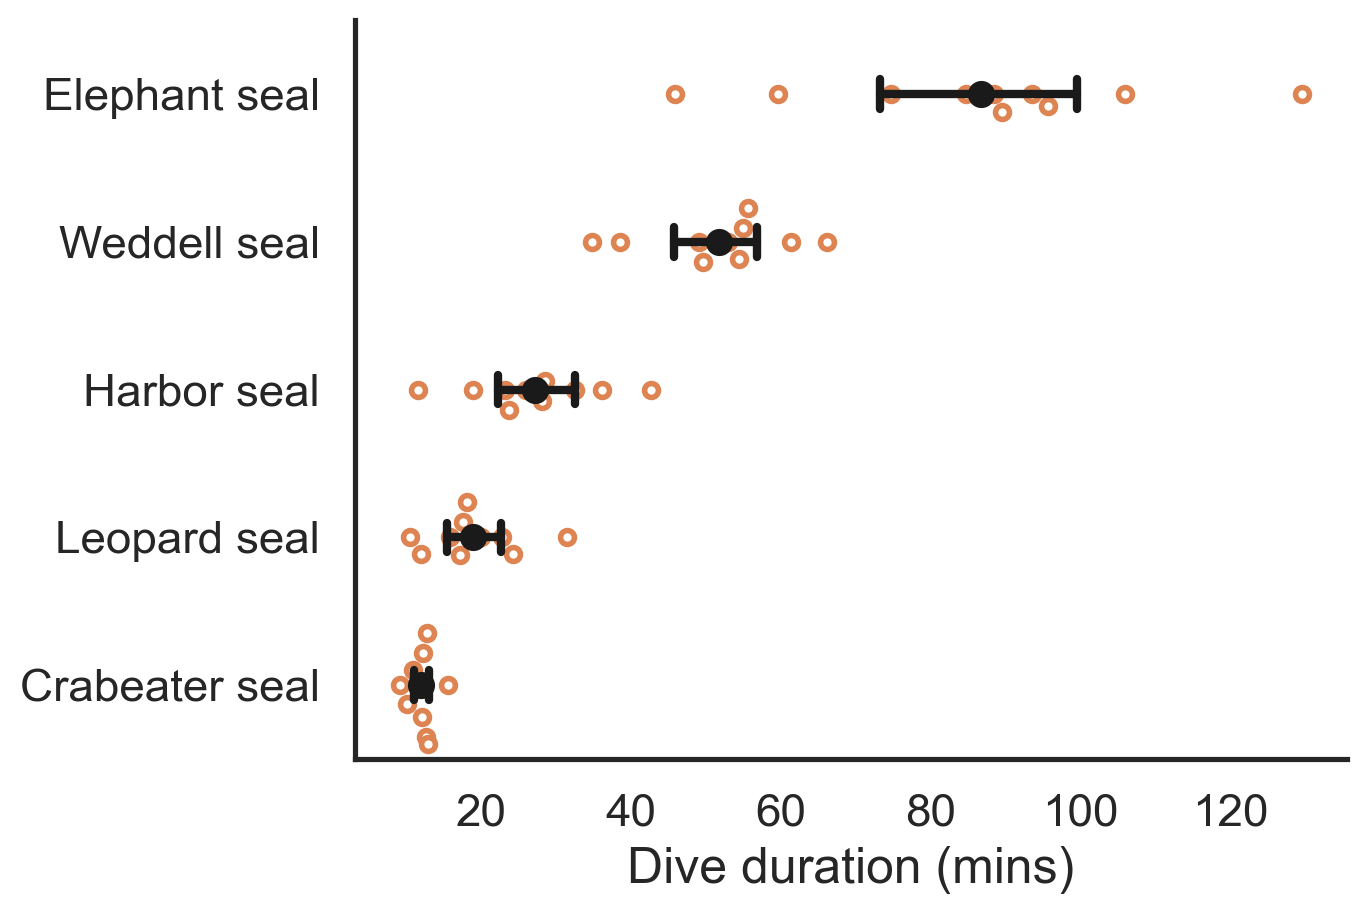

In [28]:
#| fig-align: center

ax = sns.pointplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2, color="k", linestyle="none", marker="o", linewidth=3)
sns.swarmplot(data=dives_cmp, y='group', x='dive_duration_min', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
ax.set_xlabel('Dive duration (mins)');
ax.set_ylabel('');

### Conclusion

Estimate of population parameter = Sample statistic ± Standard error of the sample statistic

For example, the estimate of a population mean:

$$\hat{\mu} = \bar{x} \pm \frac{s}{\sqrt n}$$



### This week's class notebook

Three questions:

1. **Weddell seal dive durations**: 
    
    - The same analysis as in the lecture but with a larger data set

2. **Evolution of ground finch beak depths**:
    
    - Estimate the **difference** in the means of two populations
    - This is a little more complicated and is a prelude to Friday's material

3. **Proportion of hospital patients with vancomycin-resistant intestinal *Enterococcus* bacteria**
    
    - How to estimate a population proportion from a sample of data
    - Method 1: By using a formula for the standard error of the proportion
    - Method 2: By using Monte-Carlo simulation of the sampling distribution of a proportion
